In [1]:
!pip install pandas numpy matplotlib requests lxml -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from io import StringIO
from google.colab import files

print("Бібліотеки успішно підключено!")

Бібліотеки успішно підключено!


In [3]:
uploaded = files.upload()

Saving titanic.csv to titanic.csv


In [4]:
import os

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Файл:", filename)
print("Розмір таблиці:", df.shape)

df.head()

Файл: titanic.csv
Розмір таблиці: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("Назви стовпців:")
print(df.columns.tolist())

Назви стовпців:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
print("Інформація про набір даних:")
df.info()

Інформація про набір даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
print("Кількість пропущених значень:")
print(df.isnull().sum())

Кількість пропущених значень:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
print("Описова статистика:")
df.describe()

Описова статистика:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
survived_count = df["Survived"].value_counts()

print("Кількість пасажирів:")
print(df.shape[0])

print("\nКількість загиблих:")
print(survived_count[0])

print("\nКількість виживших:")
print(survived_count[1])

survival_rate = df["Survived"].mean() * 100

print(f"\nЗагальна частка виживших: {survival_rate:.2f}%")

Кількість пасажирів:
891

Кількість загиблих:
549

Кількість виживших:
342

Загальна частка виживших: 38.38%


In [10]:
survival_by_sex = (
    df.groupby("Sex")["Survived"]
    .mean()
    .mul(100)
)

print("Частка виживших за статтю:")
print(survival_by_sex)

Частка виживших за статтю:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [11]:
survival_by_sex_df = survival_by_sex.reset_index()

survival_by_sex_df.columns = ["Стать", "Вижили, %"]

survival_by_sex_df

,Стать,"Вижили, %"
0,female,74.203822
1,male,18.890815


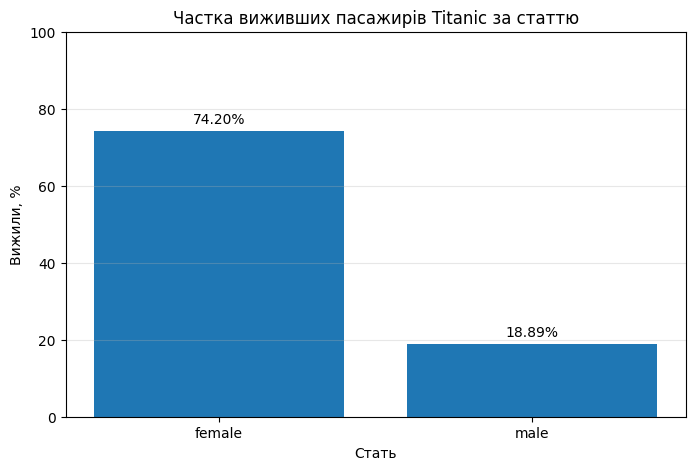

In [12]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    survival_by_sex.index,
    survival_by_sex.values
)

plt.title("Частка виживших пасажирів Titanic за статтю")
plt.xlabel("Стать")
plt.ylabel("Вижили, %")
plt.ylim(0, 100)

for bar, value in zip(bars, survival_by_sex.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

In [13]:
survival_by_class = (
    df.groupby("Pclass")["Survived"]
    .mean()
    .mul(100)
)

print("Частка виживших за класом:")
print(survival_by_class)

Частка виживших за класом:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


In [14]:
survival_by_class_df = survival_by_class.reset_index()

survival_by_class_df.columns = [
    "Клас пасажира",
    "Вижили, %"
]

survival_by_class_df

,Клас пасажира,"Вижили, %"
0,1,62.962963
1,2,47.282609
2,3,24.236253


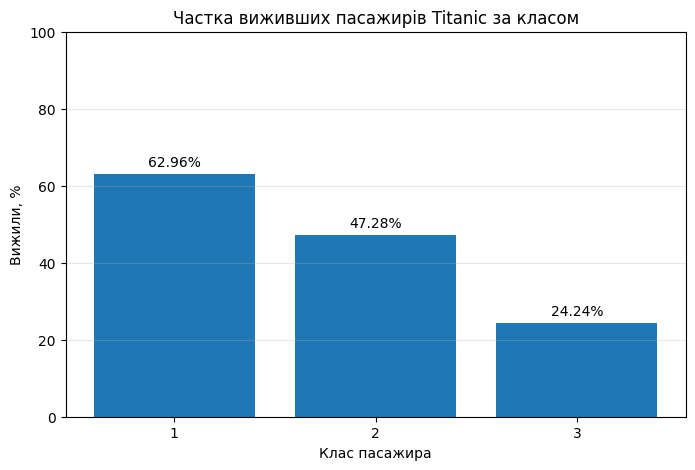

In [15]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    survival_by_class.index.astype(str),
    survival_by_class.values
)

plt.title("Частка виживших пасажирів Titanic за класом")
plt.xlabel("Клас пасажира")
plt.ylabel("Вижили, %")
plt.ylim(0, 100)

for bar, value in zip(bars, survival_by_class.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

In [16]:
url = "https://uk.wikipedia.org/wiki/Населення_України"

headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8"
}

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

response.raise_for_status()

print("Сторінка успішно завантажена.")
print("Код відповіді:", response.status_code)

Сторінка успішно завантажена.
Код відповіді: 200


In [17]:
tables = pd.read_html(
    StringIO(response.text),
    match="Коефіцієнт народжуваності в регіонах України",
    thousands=".",
    decimal=","
)

print("Кількість знайдених таблиць:", len(tables))

birth_df = tables[0]

birth_df

Кількість знайдених таблиць: 1


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


In [18]:
print("Розмір таблиці:")
print(birth_df.shape)

print("\nНазви стовпців:")
print(birth_df.columns.tolist())

Розмір таблиці:
(28, 9)

Назви стовпців:
['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']


In [22]:
# Очищення та підготовка таблиці
birth_df = birth_df.copy()

# Якщо заголовки мають кілька рівнів — об'єднуємо їх
if isinstance(birth_df.columns, pd.MultiIndex):
    birth_df.columns = [
        " ".join(str(x) for x in col if str(x) != "nan").strip()
        for col in birth_df.columns
    ]
else:
    birth_df.columns = [str(col).strip() for col in birth_df.columns]

# Перейменовуємо перший стовпець на "Регіон"
birth_df = birth_df.rename(columns={birth_df.columns[0]: "Регіон"})

# Виводимо назви стовпців, щоб перевірити
print("Назви стовпців після очищення:")
print(birth_df.columns.tolist())

birth_df.head()

Назви стовпців після очищення:
['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN


In [23]:
# Знаходимо рядок "Україна"
ukraine = birth_df[
    birth_df["Регіон"].astype(str).str.strip().str.lower() == "україна"
]

print("Рядок з даними України:")
display(ukraine)

Рядок з даними України:


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
27,Україна,22.8,20.5,15.2,12.6,7.8,11.4,11.1,8.1


In [24]:
# Потрібні роки
years = [1950, 1960, 1970, 1990, 2000, 2012, 2014, 2019]

# Знаходимо у назвах колонок відповідні роки
year_columns = {}

for year in years:
    for col in birth_df.columns:
        if str(year) in str(col):
            year_columns[year] = col
            break

print("Знайдені колонки:")
print(year_columns)

# Перевіряємо, чи всі роки знайдені
missing_years = [year for year in years if year not in year_columns]

if missing_years:
    print("Не знайдено роки:", missing_years)
else:
    # Отримуємо значення для України
    ukraine_values = ukraine[
        [year_columns[year] for year in years]
    ].iloc[0]

    # Перейменовуємо індекси на роки
    ukraine_values.index = years

    # Перетворюємо значення на числа
    ukraine_values = pd.to_numeric(
        ukraine_values.astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    print("Коефіцієнт народжуваності в Україні:")
    print(ukraine_values)

Знайдені колонки:
{1950: '1950', 1960: '1960', 1970: '1970', 1990: '1990', 2000: '2000', 2012: '2012', 2014: '2014', 2019: '2019'}
Коефіцієнт народжуваності в Україні:
1950    22.8
1960    20.5
1970    15.2
1990    12.6
2000     7.8
2012    11.4
2014    11.1
2019     8.1
Name: 27, dtype: float64


In [25]:
ukraine_table = pd.DataFrame({
    "Рік": years,
    "Коефіцієнт народжуваності": ukraine_values.values
})

ukraine_table

,Рік,Коефіцієнт народжуваності
0,1950,22.8
1,1960,20.5
2,1970,15.2
3,1990,12.6
4,2000,7.8
5,2012,11.4
6,2014,11.1
7,2019,8.1


In [26]:
min_year = ukraine_table.loc[
    ukraine_table["Коефіцієнт народжуваності"].idxmin()
]

max_year = ukraine_table.loc[
    ukraine_table["Коефіцієнт народжуваності"].idxmax()
]

print("Мінімальний показник:")
print(
    f"{int(min_year['Рік'])} рік — "
    f"{min_year['Коефіцієнт народжуваності']:.1f}‰"
)

print("\nМаксимальний показник:")
print(
    f"{int(max_year['Рік'])} рік — "
    f"{max_year['Коефіцієнт народжуваності']:.1f}‰"
)

Мінімальний показник:
2000 рік — 7.8‰

Максимальний показник:
1950 рік — 22.8‰


In [27]:
value_1950 = ukraine_table.loc[
    ukraine_table["Рік"] == 1950,
    "Коефіцієнт народжуваності"
].iloc[0]

value_2019 = ukraine_table.loc[
    ukraine_table["Рік"] == 2019,
    "Коефіцієнт народжуваності"
].iloc[0]

absolute_change = value_2019 - value_1950
percent_change = absolute_change / value_1950 * 100

print(f"Показник у 1950 році: {value_1950:.1f}‰")
print(f"Показник у 2019 році: {value_2019:.1f}‰")
print(f"Абсолютна зміна: {absolute_change:.1f}‰")
print(f"Відносна зміна: {percent_change:.2f}%")

Показник у 1950 році: 22.8‰
Показник у 2019 році: 8.1‰
Абсолютна зміна: -14.7‰
Відносна зміна: -64.47%


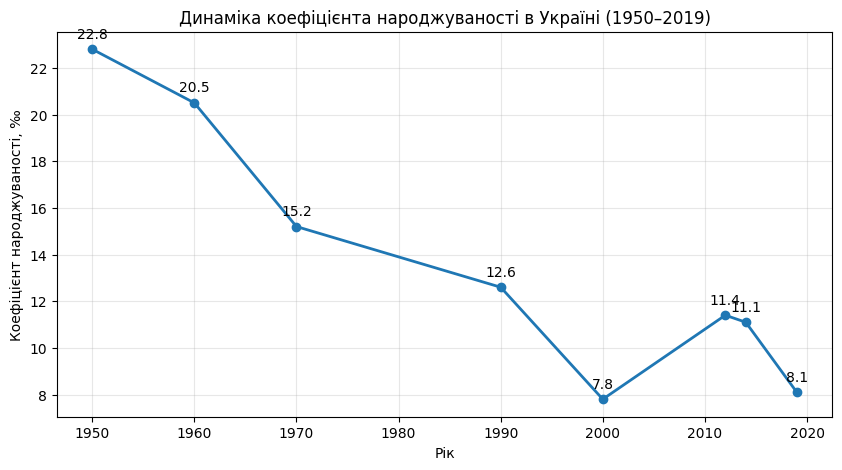

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    ukraine_table["Рік"],
    ukraine_table["Коефіцієнт народжуваності"],
    marker="o",
    linewidth=2
)

plt.title(
    "Динаміка коефіцієнта народжуваності в Україні "
    "(1950–2019)"
)

plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності, ‰")

plt.grid(True, alpha=0.3)

for x, y in zip(
    ukraine_table["Рік"],
    ukraine_table["Коефіцієнт народжуваності"]
):
    plt.annotate(
        f"{y:.1f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.show()

In [30]:
# Аналіз коефіцієнта народжуваності по регіонах за 2019 рік

# Знаходимо колонку, яка містить 2019
column_2019 = None

for col in birth_df.columns:
    if "2019" in str(col):
        column_2019 = col
        break

print("Колонка за 2019 рік:", column_2019)

# Перевіряємо, чи колонку знайдено
if column_2019 is None:
    print("Колонку 2019 року не знайдено.")
else:
    regional_2019 = birth_df[
        ["Регіон", column_2019]
    ].copy()

    # Перетворюємо значення у числовий формат
    regional_2019[column_2019] = pd.to_numeric(
        regional_2019[column_2019].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    # Видаляємо порожні значення
    regional_2019 = regional_2019.dropna()

    # Видаляємо загальний рядок "Україна"
    regional_2019 = regional_2019[
        regional_2019["Регіон"].astype(str).str.strip() != "Україна"
    ]

    print("5 регіонів з найвищим коефіцієнтом народжуваності у 2019 році:")
    display(
        regional_2019
        .sort_values(column_2019, ascending=False)
        .head(5)
    )

Колонка за 2019 рік: 2019
5 регіонів з найвищим коефіцієнтом народжуваності у 2019 році:


,Регіон,2019
25,Київ,11.0
16,Рівненська,10.7
6,Закарпатська,10.4
2,Волинська,10.1
23,Чернівецька,9.2


In [31]:
print("=" * 60)
print("ПІДСУМОК АНАЛІЗУ")
print("=" * 60)

print(f"\nTitanic:")
print(f"- кількість пасажирів: {len(df)}")
print(f"- вижили: {df['Survived'].sum()}")
print(f"- частка виживших: {df['Survived'].mean() * 100:.2f}%")

print("\nВиживання за статтю:")
for sex, value in survival_by_sex.items():
    print(f"- {sex}: {value:.2f}%")

print("\nВиживання за класом:")
for pclass, value in survival_by_class.items():
    print(f"- {pclass} клас: {value:.2f}%")

print("\nНароджуваність в Україні:")
print(f"- 1950 рік: {value_1950:.1f}‰")
print(f"- 2019 рік: {value_2019:.1f}‰")
print(f"- зміна: {absolute_change:.1f}‰")
print(f"- відносна зміна: {percent_change:.2f}%")

ПІДСУМОК АНАЛІЗУ

Titanic:
- кількість пасажирів: 891
- вижили: 342
- частка виживших: 38.38%

Виживання за статтю:
- female: 74.20%
- male: 18.89%

Виживання за класом:
- 1 клас: 62.96%
- 2 клас: 47.28%
- 3 клас: 24.24%

Народжуваність в Україні:
- 1950 рік: 22.8‰
- 2019 рік: 8.1‰
- зміна: -14.7‰
- відносна зміна: -64.47%


Висновок: В ході виконання роботи було проведено аналіз набору даних Titanic та таблиці «Коефіцієнт народжуваності в регіонах України (1950—2019)». Для роботи використовувалися бібліотеки Python `pandas`, `numpy`, `matplotlib` та `requests`.

Під час аналізу набору Titanic було виконано зчитування даних, перегляд структури таблиці, визначення типів даних, кількості пропущених значень та отримання описової статистики. Також було досліджено частку виживших пасажирів залежно від статі та класу.

За результатами аналізу було встановлено, що загальна частка виживших у наборі становить приблизно 38,38%. Частка виживших відрізняється між чоловіками та жінками, а також між пасажирами різних класів. Для наочного представлення результатів було побудовано два графіки.

Далі за допомогою бібліотеки `pandas` та функції `read_html()` було зчитано таблицю коефіцієнта народжуваності в регіонах України з Вікіпедії. Дані було очищено від пропущених значень та перетворено у числовий формат. Для України було проаналізовано показники за 1950, 1960, 1970, 1990, 2000, 2012, 2014 та 2019 роки.

Аналіз показав загальне зниження коефіцієнта народжуваності в Україні: з 22,8‰ у 1950 році до 8,1‰ у 2019 році. При цьому в окремі періоди спостерігалися зміни напрямку динаміки, зокрема зростання показника між 2000 та 2012 роками.

В результаті роботи було отримано практичні навички зчитування, очищення, групування та статистичного аналізу даних у Python, а також побудови графіків за допомогою бібліотеки `matplotlib`.
